In [ ]:
#1 : Monter Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Créer le dossier projet sur Drive
import os
PROJECT_DIR = '/content/drive/MyDrive/nerf_parallele'
os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/data/frames', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/data/poses', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/checkpoints', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/results', exist_ok=True)

print(f" Google Drive monté")
print(f" Dossier projet : {PROJECT_DIR}")

Mounted at /content/drive
✅ Google Drive monté
✅ Dossier projet : /content/drive/MyDrive/nerf_parallele


In [ ]:
#2 : Vérification GPU
import torch

print("="*45)
print("VÉRIFICATION ENVIRONNEMENT GPU")
print("="*45)

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram     = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f" GPU détecté   : {gpu_name}")
    print(f" VRAM          : {vram:.1f} Go")
    print(f" CUDA version  : {torch.version.cuda}")
    print(f" PyTorch       : {torch.__version__}")
else:
    print("Pas de GPU — vérifie le type d'exécution !")

print("="*45)

# Configurer le device une fois pour toutes
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n Device utilisé : {device}")

VÉRIFICATION ENVIRONNEMENT GPU
 GPU détecté   : Tesla T4
 VRAM          : 15.6 Go
 CUDA version  : 12.8
 PyTorch       : 2.10.0+cu128

 Device utilisé : cuda


In [ ]:
#3 : Installation des packages
print("Installation des dépendances")

!pip install -q opencv-python-headless
!pip install -q imageio imageio-ffmpeg
!pip install -q pytorch-msssim
!pip install -q einops
!pip install -q open3d
!pip install -q tqdm
!pip install -q matplotlib

print("Toutes les dépendances installées !")

# Imports globaux
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import time
from tqdm import tqdm
from multiprocessing import Pool

print("Imports OK !")

Installation des dépendances
Toutes les dépendances installées !
Imports OK !


In [ ]:
!wget http://cseweb.ucsd.edu/~viscomp/projects/LF/papers/ECCV20/nerf/nerf_example_data.zip -O nerf_data.zip

--2026-04-22 09:10:06--  http://cseweb.ucsd.edu/~viscomp/projects/LF/papers/ECCV20/nerf/nerf_example_data.zip
Resolving cseweb.ucsd.edu (cseweb.ucsd.edu)... 132.239.8.30
Connecting to cseweb.ucsd.edu (cseweb.ucsd.edu)|132.239.8.30|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://cseweb.ucsd.edu//~viscomp/projects/LF/papers/ECCV20/nerf/nerf_example_data.zip [following]
--2026-04-22 09:10:06--  https://cseweb.ucsd.edu//~viscomp/projects/LF/papers/ECCV20/nerf/nerf_example_data.zip
Connecting to cseweb.ucsd.edu (cseweb.ucsd.edu)|132.239.8.30|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 370385516 (353M) [application/zip]
Saving to: ‘nerf_data.zip’

nerf_data.zip       100%[===================>] 353.23M  8.73MB/s    in 41s     

2026-04-22 09:10:47 (8.54 MB/s) - ‘nerf_data.zip’ saved [370385516/370385516]



In [ ]:
!unzip nerf_data.zip

Archive:  nerf_data.zip
   creating: nerf_llff_data/
   creating: nerf_llff_data/fern/
  inflating: nerf_llff_data/fern/database.db  
   creating: nerf_llff_data/fern/images_4/
  inflating: nerf_llff_data/fern/images_4/image007.png  
  inflating: nerf_llff_data/fern/images_4/image008.png  
  inflating: nerf_llff_data/fern/images_4/image002.png  
  inflating: nerf_llff_data/fern/images_4/image010.png  
  inflating: nerf_llff_data/fern/images_4/image011.png  
  inflating: nerf_llff_data/fern/images_4/image018.png  
  inflating: nerf_llff_data/fern/images_4/image014.png  
  inflating: nerf_llff_data/fern/images_4/image005.png  
  inflating: nerf_llff_data/fern/images_4/image009.png  
  inflating: nerf_llff_data/fern/images_4/image004.png  
  inflating: nerf_llff_data/fern/images_4/image016.png  
  inflating: nerf_llff_data/fern/images_4/image015.png  
  inflating: nerf_llff_data/fern/images_4/image001.png  
  inflating: nerf_llff_data/fern/images_4/image000.png  
  inflating: nerf_llff_da

In [ ]:
!ls

drive  nerf_data.zip  nerf_llff_data  nerf_synthetic  sample_data


In [ ]:
!ls nerf_synthetic

lego


In [ ]:
!ls nerf_synthetic/lego

test   transforms_test.json   transforms_val.json
train  transforms_train.json  val


 Informations du dataset :
  Nombre d'images train : 100
  Champ de vision (FOV) : 0.6911 rad
  = 39.6°

 Exemple de pose caméra (frame 0) :
  Fichier image : ./train/r_0
  Matrice de transformation (4×4) :
[[-1.     0.004 -0.013 -0.054]
 [-0.014 -0.3    0.954  3.845]
 [-0.     0.954  0.3    1.208]
 [ 0.     0.     0.     1.   ]]


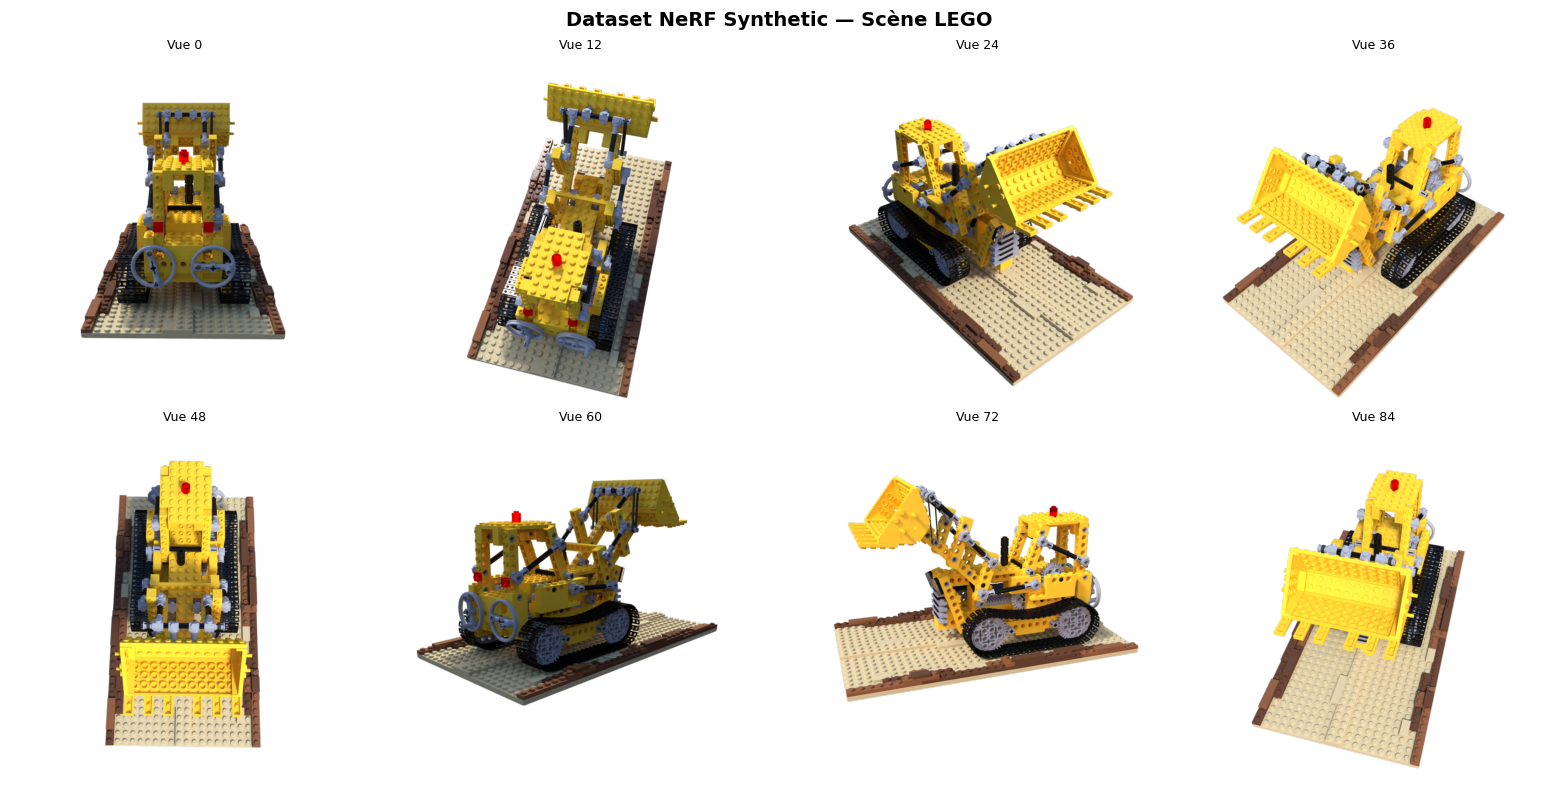

Aperçu sauvegardé sur Drive !


In [ ]:
#5 : Explorer le dataset
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Charger les métadonnées d'entraînement
with open('/content/nerf_synthetic/lego/transforms_train.json') as f:
    meta = json.load(f)

print(f" Informations du dataset :")
print(f"  Nombre d'images train : {len(meta['frames'])}")
print(f"  Champ de vision (FOV) : {meta['camera_angle_x']:.4f} rad")
print(f"  = {np.degrees(meta['camera_angle_x']):.1f}°")

# Afficher la structure d'une pose caméra
frame0 = meta['frames'][0]
print(f"\n Exemple de pose caméra (frame 0) :")
print(f"  Fichier image : {frame0['file_path']}")
print(f"  Matrice de transformation (4×4) :")
mat = np.array(frame0['transform_matrix'])
print(mat.round(3))

# Afficher quelques images du dataset
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Dataset NeRF Synthetic — Scène LEGO", fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    if i < len(meta['frames']):
        img_path = f"/content/nerf_synthetic/lego/{meta['frames'][i*12]['file_path']}.png"
        if os.path.exists(img_path):
            img = mpimg.imread(img_path)
            ax.imshow(img)
            ax.set_title(f"Vue {i*12}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/nerf_parallele/results/dataset_preview.png',
            dpi=100, bbox_inches='tight')
plt.show()
print("Aperçu sauvegardé sur Drive !")

In [ ]:
#6:Module extraction parallèle

frame_extractor_code = '''
import cv2
import os
import time
import numpy as np
from multiprocessing import Pool
from functools import partial

def process_single_frame(args):
    """
    Traite UNE frame — exécutée en PARALLÈLE par chaque worker.
    C'est la fonction qui tourne sur chaque cœur CPU simultanément.
    """
    frame_idx, frame_data, output_dir, target_size = args

    # Redimensionner la frame
    frame_resized = cv2.resize(frame_data, target_size,
                               interpolation=cv2.INTER_AREA)

    # Sauvegarder en PNG
    output_path = os.path.join(output_dir, f"frame_{frame_idx:04d}.png")
    cv2.imwrite(output_path, frame_resized)

    return frame_idx, output_path


def extract_frames_sequential(video_path, output_dir,
                               target_size=(400, 300), sample_rate=3):
    """VERSION SÉQUENTIELLE — pour mesurer le baseline."""
    os.makedirs(output_dir, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    saved, idx = 0, 0
    start = time.time()

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if idx % sample_rate == 0:
            path = os.path.join(output_dir, f"frame_{saved:04d}.png")
            frame_r = cv2.resize(frame, target_size)
            cv2.imwrite(path, frame_r)
            saved += 1
        idx += 1

    cap.release()
    elapsed = time.time() - start
    return saved, elapsed


def extract_frames_parallel(video_path, output_dir,
                             target_size=(400, 300),
                             sample_rate=3, num_workers=4):
    """
    VERSION PARALLÈLE — utilise multiprocessing.Pool.

    PARALLÉLISME : chaque frame est traitée par un worker indépendant.
    Type : Parallélisme de données (même tâche, données différentes).
    """
    os.makedirs(output_dir, exist_ok=True)

    # 1. Lire TOUTES les frames en mémoire d'abord
    cap = cv2.VideoCapture(video_path)
    frames_data = []
    idx = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if idx % sample_rate == 0:
            frames_data.append(
                (len(frames_data), frame, output_dir, target_size)
            )
        idx += 1
    cap.release()

    # 2. Traitement PARALLÈLE avec Pool
    start = time.time()
    with Pool(processes=num_workers) as pool:
        results = pool.map(process_single_frame, frames_data)
    elapsed = time.time() - start

    return len(results), elapsed
'''

# Sauvegarder le module
with open('/content/frame_extractor.py', 'w', encoding='utf-8') as f:
    f.write(frame_extractor_code)

# Copier sur Drive pour persistance
!cp /content/frame_extractor.py \
   '/content/drive/MyDrive/nerf_parallele/src/'

print("Module frame_extractor.py créé et sauvegardé !")

Module frame_extractor.py créé et sauvegardé !


In [ ]:
!mkdir -p /content/drive/MyDrive/nerf_parallele/src

In [ ]:
!ls /content/drive/MyDrive/nerf_parallele/src/

frame_extractor.py  __pycache__


In [ ]:
# ════════════════════════════════════════════════════════════
# PHASE 3 — Extraction des frames : Séquentiel vs Parallèle
# ════════════════════════════════════════════════════════════
import os
import time
import json
import numpy as np
import cv2
from PIL import Image
from multiprocessing import Pool
import matplotlib.pyplot as plt

# ── Paramètres ───────────────────────────────────────────────
DATASET_DIR = "/content/nerf_synthetic/lego"   #  dataset LEGO
OUTPUT_SEQ  = "/content/frames_sequential"      # dossier version séquentielle
OUTPUT_PAR  = "/content/frames_parallel"        # dossier version parallèle
TARGET_SIZE = (100, 100)                        # taille cible des images

os.makedirs(OUTPUT_SEQ, exist_ok=True)
os.makedirs(OUTPUT_PAR, exist_ok=True)

# ── Charger la liste des images depuis le JSON ────────────────
with open(f"{DATASET_DIR}/transforms_train.json") as f:
    meta = json.load(f)

# Construire la liste des chemins d'images
image_paths = []
for frame in meta["frames"]:
    path = os.path.join(DATASET_DIR, frame["file_path"] + ".png")
    if os.path.exists(path):
        image_paths.append(path)

print(f" {len(image_paths)} images trouvées dans le dataset LEGO")

 100 images trouvées dans le dataset LEGO


In [ ]:
# ════════════════════════════════════════════════════════════
# VERSION SÉQUENTIELLE — une image traitée à la fois
# ════════════════════════════════════════════════════════════

def traiter_image_sequentiel(img_path, output_dir, taille):
    """
    Charge, redimensionne et sauvegarde UNE image.
    En séquentiel : cette fonction est appelée une par une.
    """
    nom_fichier = os.path.basename(img_path)
    img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
    img = cv2.resize(img, taille)
    cv2.imwrite(os.path.join(output_dir, nom_fichier), img)


print("  Lancement version SÉQUENTIELLE")
debut = time.time()

for chemin in image_paths:
    traiter_image_sequentiel(chemin, OUTPUT_SEQ, TARGET_SIZE)

temps_sequentiel = time.time() - debut
print(f" Séquentiel terminé en : {temps_sequentiel:.3f} secondes")

  Lancement version SÉQUENTIELLE
 Séquentiel terminé en : 1.563 secondes


In [ ]:
# ════════════════════════════════════════════════════════════
# VERSION PARALLÈLE — plusieurs images traitées en même temps
# ════════════════════════════════════════════════════════════

def traiter_image_parallele(args):
    """
    Même traitement qu'avant, mais cette fonction sera exécutée
    par PLUSIEURS workers en même temps (un par cœur CPU).
    Elle reçoit ses arguments sous forme de tuple.
    """
    img_path, output_dir, taille = args
    nom_fichier = os.path.basename(img_path)
    img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
    img = cv2.resize(img, taille)
    cv2.imwrite(os.path.join(output_dir, nom_fichier), img)


# Préparer les arguments pour chaque image
arguments = [(chemin, OUTPUT_PAR, TARGET_SIZE) for chemin in image_paths]

print(" Lancement version PARALLÈLE (4 workers)")
debut = time.time()

# Pool de 4 workers : 4 images traitées simultanément
with Pool(processes=4) as pool:
    pool.map(traiter_image_parallele, arguments)

temps_parallele = time.time() - debut
print(f" Parallèle terminé en : {temps_parallele:.3f} secondes")

 Lancement version PARALLÈLE (4 workers)
 Parallèle terminé en : 1.213 secondes



         RÉSULTATS EXTRACTION
  Images traitées  : 100
  Séquentiel       : 1.563 s
  Parallèle        : 1.213 s
   Speedup       : 1.29×

  Mesure du speedup selon le nombre de workers
   1 worker(s) → 1.663s → Speedup : 0.94×
   2 worker(s) → 1.171s → Speedup : 1.33×
   4 worker(s) → 1.226s → Speedup : 1.28×


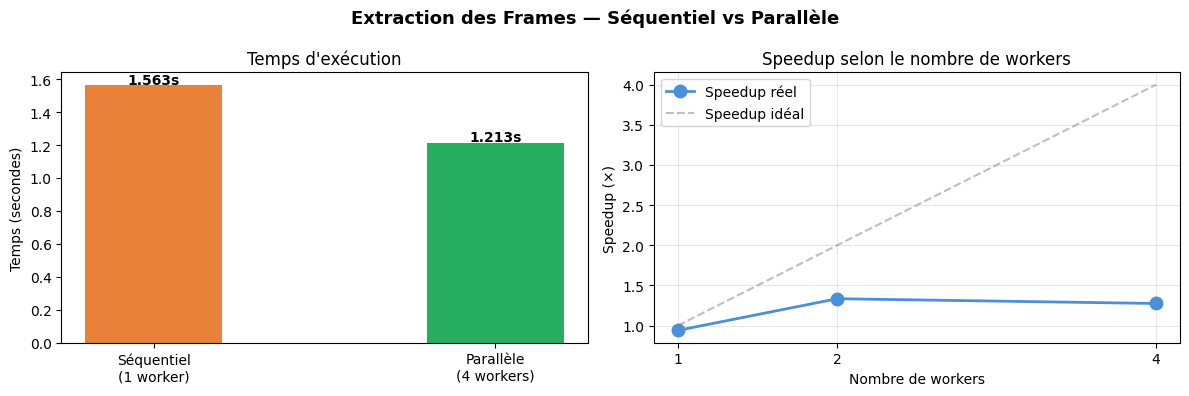


 Graphe sauvegardé sur Drive !


In [ ]:
# ════════════════════════════════════════════════════════════
# COMPARAISON — Speedup mesuré
# ════════════════════════════════════════════════════════════

speedup = temps_sequentiel / temps_parallele

print("\n" + "="*45)
print("         RÉSULTATS EXTRACTION")
print("="*45)
print(f"  Images traitées  : {len(image_paths)}")
print(f"  Séquentiel       : {temps_sequentiel:.3f} s")
print(f"  Parallèle        : {temps_parallele:.3f} s")
print(f"   Speedup       : {speedup:.2f}×")
print("="*45)

# ── Graphe comparatif ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Extraction des Frames — Séquentiel vs Parallèle",
             fontsize=13, fontweight="bold")

# Graphe 1 : Temps
methodes = ["Séquentiel\n(1 worker)", "Parallèle\n(4 workers)"]
temps    = [temps_sequentiel, temps_parallele]
couleurs = ["#E8813A", "#27AE60"]

barres = axes[0].bar(methodes, temps, color=couleurs, width=0.4)
axes[0].set_ylabel("Temps (secondes)")
axes[0].set_title("Temps d'exécution")
for barre, t in zip(barres, temps):
    axes[0].text(barre.get_x() + barre.get_width()/2,
                 barre.get_height() + 0.01,
                 f"{t:.3f}s", ha="center", fontweight="bold")

# Graphe 2 : Speedup selon le nombre de workers
print("\n  Mesure du speedup selon le nombre de workers")
workers_list = [1, 2, 4]
speedups     = []

for n_workers in workers_list:
    debut = time.time()
    with Pool(processes=n_workers) as pool:
        pool.map(traiter_image_parallele, arguments)
    t = time.time() - debut
    sp = temps_sequentiel / t
    speedups.append(sp)
    print(f"   {n_workers} worker(s) → {t:.3f}s → Speedup : {sp:.2f}×")

axes[1].plot(workers_list, speedups, "o-",
             color="#4A90D9", linewidth=2, markersize=9, label="Speedup réel")
axes[1].plot(workers_list, workers_list, "--",
             color="gray", alpha=0.5, label="Speedup idéal")
axes[1].set_xlabel("Nombre de workers")
axes[1].set_ylabel("Speedup (×)")
axes[1].set_title("Speedup selon le nombre de workers")
axes[1].legend()
axes[1].set_xticks(workers_list)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nerf_parallele/results/speedup_extraction.png",
            dpi=120, bbox_inches="tight")
plt.show()
print("\n Graphe sauvegardé sur Drive !")

In [ ]:
!ls

drive		 frames_sequential  nerf_llff_data  sample_data
frames_parallel  nerf_data.zip	    nerf_synthetic


In [ ]:
!ls nerf_synthetic

lego


In [ ]:
# ════════════════════════════════════════════════════════════
# PHASE 4 — Chargement des images et poses caméra
# ════════════════════════════════════════════════════════════
import os
import json
import numpy as np
import cv2
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

DATASET_DIR = "/content/nerf_synthetic/lego"
IMG_SIZE    = (100, 100)   # on travaille en petite résolution pour la rapidité

def charger_dataset(dossier, split="train", taille=(100, 100)):
    """
    Charge toutes les images + poses caméra d'un dataset NeRF Synthetic.

    Retourne :
      images : tableau numpy [N, H, W, 4]  — N images RGBA
      poses  : tableau numpy [N, 4, 4]     — N matrices de pose caméra
      focale : float                        — longueur focale en pixels
    """
    # Lire le fichier JSON
    chemin_json = os.path.join(dossier, f"transforms_{split}.json")
    with open(chemin_json) as f:
        meta = json.load(f)

    H, W = taille
    # La focale se calcule à partir du champ de vision horizontal
    focale = 0.5 * W / np.tan(0.5 * meta["camera_angle_x"])

    images, poses = [], []

    for frame in meta["frames"]:
        # Charger l'image (RGBA = 4 canaux)
        chemin_img = os.path.join(dossier, frame["file_path"] + ".png")
        img = cv2.imread(chemin_img, cv2.IMREAD_UNCHANGED)
        img = cv2.resize(img, (W, H))
        img = img.astype(np.float32) / 255.0   # valeurs entre 0 et 1
        images.append(img)

        # Charger la matrice de pose (position + orientation caméra)
        poses.append(np.array(frame["transform_matrix"], dtype=np.float32))

    images = np.stack(images)   # [N, H, W, 4]
    poses  = np.stack(poses)    # [N, 4, 4]

    return images, poses, focale


# ── Charger train et test ─────────────────────────────────────
print(" Chargement du dataset LEGO")
images_train, poses_train, focale = charger_dataset(DATASET_DIR, "train", IMG_SIZE)
images_test,  poses_test,  _      = charger_dataset(DATASET_DIR, "test",  IMG_SIZE)

print(f"\n Dataset chargé !")
print(f"   Train  : {images_train.shape[0]} images  {images_train.shape[1]}×{images_train.shape[2]}")
print(f"   Test   : {images_test.shape[0]}  images  {images_test.shape[1]}×{images_test.shape[2]}")
print(f"   Focale : {focale:.2f} pixels")

 Chargement du dataset LEGO

 Dataset chargé !
   Train  : 100 images  100×100
   Test   : 200  images  100×100
   Focale : 138.89 pixels


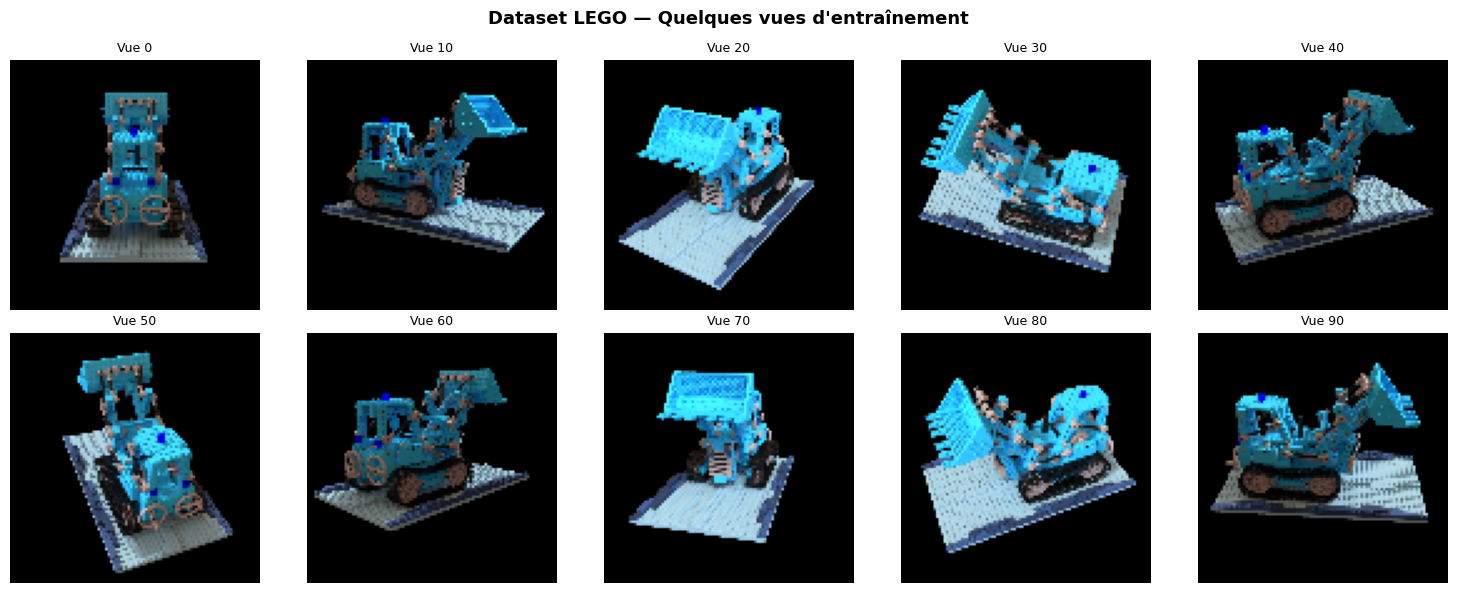

 Aperçu du dataset sauvegardé !


In [ ]:
# ════════════════════════════════════════════════════════════
# Visualiser quelques images du dataset
# ════════════════════════════════════════════════════════════

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Dataset LEGO — Quelques vues d'entraînement",
             fontsize=13, fontweight="bold")

for i, ax in enumerate(axes.flat):
    # Afficher uniquement les canaux RGB (ignorer alpha)
    ax.imshow(images_train[i * 10, :, :, :3])
    ax.set_title(f"Vue {i * 10}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/nerf_parallele/results/dataset_vues.png",
            dpi=100, bbox_inches="tight")
plt.show()
print(" Aperçu du dataset sauvegardé !")

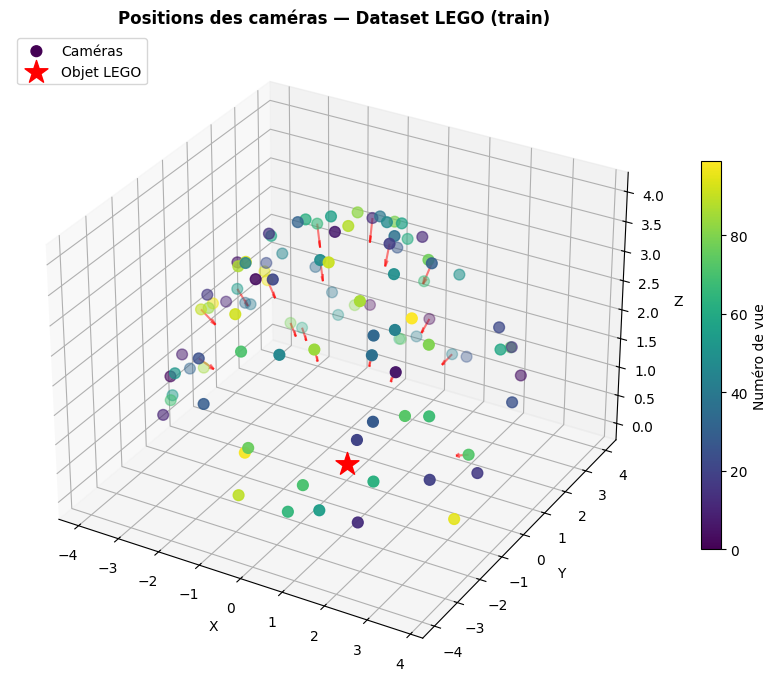

 Visualisation des poses sauvegardée !


In [ ]:
# ════════════════════════════════════════════════════════════
# Visualiser les positions des caméras autour de l'objet
# ════════════════════════════════════════════════════════════

def visualiser_poses(poses, titre="Positions des caméras"):
    """
    Affiche en 3D où se trouvait chaque caméra quand la photo a été prise.
    Chaque point = une caméra. La flèche = direction où elle regarde.
    """
    fig = plt.figure(figsize=(9, 7))
    ax  = fig.add_subplot(111, projection="3d")

    # La position de chaque caméra = colonne de translation de la matrice
    positions = poses[:, :3, 3]   # [N, 3]

    # Afficher les positions (couleur = ordre chronologique)
    sc = ax.scatter(positions[:, 0], positions[:, 1], positions[:, 2],
                    c=range(len(positions)), cmap="viridis",
                    s=60, zorder=5, label="Caméras")
    plt.colorbar(sc, ax=ax, label="Numéro de vue", shrink=0.6)

    # Afficher la direction de regard de quelques caméras
    pas = max(1, len(poses) // 15)   # afficher ~15 flèches max
    for i in range(0, len(poses), pas):
        pos = poses[i, :3, 3]
        # La 3ème colonne de la rotation = axe Z caméra = direction de regard
        direction = -poses[i, :3, 2] * 0.4
        ax.quiver(pos[0], pos[1], pos[2],
                  direction[0], direction[1], direction[2],
                  color="red", alpha=0.5, arrow_length_ratio=0.3)

    # L'objet LEGO est au centre (0, 0, 0)
    ax.scatter([0], [0], [0], c="red", s=300,
               marker="*", zorder=10, label="Objet LEGO")

    ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
    ax.set_title(titre, fontsize=12, fontweight="bold")
    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.savefig("/content/drive/MyDrive/nerf_parallele/results/poses_cameras.png",
                dpi=110, bbox_inches="tight")
    plt.show()
    print(" Visualisation des poses sauvegardée !")


visualiser_poses(poses_train, "Positions des caméras — Dataset LEGO (train)")

In [ ]:
# ════════════════════════════════════════════════════════════
# PHASE 5.1 — Positional Encoding
# ════════════════════════════════════════════════════════════
import torch
import torch.nn as nn

class PositionalEncoding(nn.Module):
    """
    Transforme une coordonnée 3D simple en un vecteur riche
    en informations (hautes fréquences).

    Sans ça, le réseau ne peut pas reproduire les détails fins
    comme les bords, les textures, les reflets.

    Exemple :
      Entrée  → (x, y, z)           : 3 valeurs
      Sortie  → sin/cos à L niveaux : 63 valeurs (si L=10)
    """
    def __init__(self, nb_frequences=10):
        super().__init__()
        # Fréquences : 1, 2, 4, 8, ... 2^(L-1)
        freqs = 2.0 ** torch.linspace(0, nb_frequences - 1, nb_frequences)
        self.register_buffer("freqs", freqs)
        self.nb_frequences = nb_frequences

    def forward(self, x):
        # x : [N, 3]
        resultat = [x]  # garder les coordonnées originales
        for freq in self.freqs:
            resultat.append(torch.sin(freq * x))
            resultat.append(torch.cos(freq * x))
        return torch.cat(resultat, dim=-1)

    def dim_sortie(self, dim_entree=3):
        return dim_entree + dim_entree * 2 * self.nb_frequences


#Test rapide
enc_position  = PositionalEncoding(nb_frequences=10)
enc_direction = PositionalEncoding(nb_frequences=4)

test = torch.randn(5, 3)
print(f" Positional Encoding")
print(f"   Entrée  : {test.shape}")
print(f"   Sortie  (positions)  : {enc_position(test).shape}   → {enc_position.dim_sortie()} valeurs")
print(f"   Sortie  (directions) : {enc_direction(test).shape}  → {enc_direction.dim_sortie()} valeurs")

 Positional Encoding
   Entrée  : torch.Size([5, 3])
   Sortie  (positions)  : torch.Size([5, 63])   → 63 valeurs
   Sortie  (directions) : torch.Size([5, 27])  → 27 valeurs


In [ ]:
# ════════════════════════════════════════════════════════════
# PHASE 5.2 — Le réseau de neurones NeRF
# ════════════════════════════════════════════════════════════

class ReseauNeRF(nn.Module):
    """
    Réseau de neurones qui apprend la scène 3D.

    Pour chaque point (x,y,z) + direction de vue :
      → Prédit la couleur RGB et la densité σ

    La densité σ dit "est-ce qu'il y a de la matière ici ?"
    La couleur RGB dit "de quelle couleur est cette matière ?"
    """
    def __init__(self,
                 dim_position=63,    # sortie de enc_position
                 dim_direction=27,   # sortie de enc_direction
                 dim_cache=256):     # taille des couches cachées
        super().__init__()

        # ── Partie 1 : traiter la position (4 couches) ────────
        self.couches_debut = nn.Sequential(
            nn.Linear(dim_position, dim_cache), nn.ReLU(),
            nn.Linear(dim_cache,    dim_cache), nn.ReLU(),
            nn.Linear(dim_cache,    dim_cache), nn.ReLU(),
            nn.Linear(dim_cache,    dim_cache), nn.ReLU(),
        )

        # ── Skip connection : réinjecter la position ──────────
        # (technique classique pour éviter l'oubli en profondeur)
        self.couche_skip = nn.Sequential(
            nn.Linear(dim_cache + dim_position, dim_cache), nn.ReLU(),
        )

        # ── Partie 2 : encore 3 couches ───────────────────────
        self.couches_fin = nn.Sequential(
            nn.Linear(dim_cache, dim_cache), nn.ReLU(),
            nn.Linear(dim_cache, dim_cache), nn.ReLU(),
            nn.Linear(dim_cache, dim_cache), nn.ReLU(),
        )

        # ── Tête densité (ne dépend PAS de la direction) ──────
        self.tete_densite = nn.Linear(dim_cache, 1)

        # ── Tête couleur (dépend de la direction de vue) ──────
        self.tete_couleur = nn.Sequential(
            nn.Linear(dim_cache + dim_direction, dim_cache // 2),
            nn.ReLU(),
            nn.Linear(dim_cache // 2, 3),
            nn.Sigmoid()   # couleur entre 0 et 1
        )

    def forward(self, positions_enc, directions_enc):
        """
         PARALLÉLISME GPU :
        Toutes les lignes du batch sont traitées SIMULTANÉMENT.
        Si batch = 1024 rayons × 64 points = 65 536 points
        → tous calculés en même temps sur les cœurs CUDA du GPU.

        positions_enc  : [N, 63]
        directions_enc : [N, 27]
        """
        # Partie 1
        x = self.couches_debut(positions_enc)

        # Skip connection : on réinjecte les coordonnées de départ
        x = torch.cat([x, positions_enc], dim=-1)
        x = self.couche_skip(x)

        # Partie 2
        x = self.couches_fin(x)

        # Densité (≥ 0 obligatoire)
        densite = torch.relu(self.tete_densite(x)).squeeze(-1)

        # Couleur (conditionnée par la direction)
        x_couleur = torch.cat([x, directions_enc], dim=-1)
        couleur   = self.tete_couleur(x_couleur)

        return couleur, densite   # [N, 3], [N]


# ── Test du réseau ────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"  Device : {device}")

modele = ReseauNeRF().to(device)

# Simuler un batch de 1024 points
pos_test = torch.randn(1024, 63).to(device)
dir_test = torch.randn(1024, 27).to(device)

couleurs, densites = modele(pos_test, dir_test)

nb_params = sum(p.numel() for p in modele.parameters())
print(f"\n Réseau NeRF créé !")
print(f"   Paramètres totaux : {nb_params:,}")
print(f"   Entrée positions  : {pos_test.shape}")
print(f"   Sortie couleurs   : {couleurs.shape}   (RGB entre 0 et 1)")
print(f"   Sortie densités   : {densites.shape}  (≥ 0)")

  Device : cuda

 Réseau NeRF créé !
   Paramètres totaux : 530,052
   Entrée positions  : torch.Size([1024, 63])
   Sortie couleurs   : torch.Size([1024, 3])   (RGB entre 0 et 1)
   Sortie densités   : torch.Size([1024])  (≥ 0)


 Test du pipeline complet
 Pipeline OK !
   Rayons     : torch.Size([2500, 3])
   Points 3D  : torch.Size([2500, 32, 3])
   Image rendue : (50, 50, 3)  (valeurs : 0.00 → 0.00)


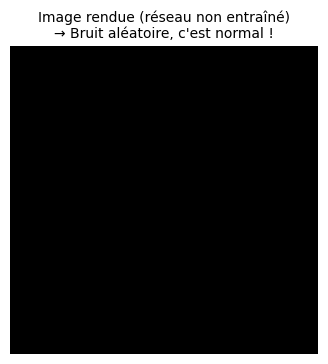


  Après entraînement, cette image deviendra le vrai LEGO !


In [ ]:
# ════════════════════════════════════════════════════════════
# PHASE 5.3 — Rayons + Volume Rendering
# ════════════════════════════════════════════════════════════

def generer_rayons(H, W, focale, pose):
    """
    Pour chaque pixel de l'image, génère un rayon qui part
    de la caméra et traverse la scène.

     Entièrement vectorisé : pas de boucle sur les pixels.
    Tous les H×W rayons sont calculés en une seule opération.

    Retourne :
      origines   : [H*W, 3]  — d'où part chaque rayon
      directions : [H*W, 3]  — où va chaque rayon
    """
    # Grille de coordonnées pixels
    j, i = torch.meshgrid(
        torch.arange(H, dtype=torch.float32),
        torch.arange(W, dtype=torch.float32),
        indexing="ij"
    )

    # Direction de chaque rayon en espace caméra
    dirs = torch.stack([
         (i - W * 0.5) / focale,
        -(j - H * 0.5) / focale,
        -torch.ones_like(i)
    ], dim=-1)   # [H, W, 3]

    # Passer en espace monde avec la matrice de rotation de la pose
    rotation  = pose[:3, :3]                              # [3, 3]
    dirs_monde = (dirs.reshape(-1, 3) @ rotation.T)       # [H*W, 3]

    # L'origine est la position de la caméra (même pour tous les rayons)
    origines = pose[:3, 3].expand(dirs_monde.shape[0], -1)

    return origines, dirs_monde


def echantillonner_points(origines, directions, proche=2.0, loin=6.0, nb_pts=64):
    """
    Place des points régulièrement espacés sur chaque rayon,
    entre les distances 'proche' et 'loin'.

     Vectorisé : tous les rayons × tous les points en une fois.

    Retourne :
      points : [N_rayons, nb_pts, 3]  — coordonnées 3D des points
      t_vals : [N_rayons, nb_pts]     — distances le long du rayon
    """
    N = origines.shape[0]

    # Distances uniformes + légère perturbation aléatoire
    t = torch.linspace(0., 1., nb_pts, device=origines.device)
    t_vals = proche * (1. - t) + loin * t                  # [nb_pts]
    t_vals = t_vals.expand(N, nb_pts)                       # [N, nb_pts]

    # Petite perturbation pour éviter les artefacts de grille
    bruit = torch.rand_like(t_vals) * (loin - proche) / nb_pts
    t_vals = t_vals + bruit

    # Coordonnées 3D : P = O + t * D
    points = origines[:, None, :] + directions[:, None, :] * t_vals[:, :, None]

    return points, t_vals


def volume_rendering(couleurs, densites, t_vals):
    """
    Transforme les couleurs et densités le long d'un rayon
    en une couleur finale pour le pixel.

    C'est la formule physique de l'accumulation de lumière.
     Entièrement vectorisé sur GPU — aucune boucle.

    couleurs : [N_rayons, nb_pts, 3]
    densites : [N_rayons, nb_pts]
    t_vals   : [N_rayons, nb_pts]
    """
    # Distance entre points consécutifs
    deltas = t_vals[:, 1:] - t_vals[:, :-1]
    deltas = torch.cat([deltas, torch.full_like(deltas[:, :1], 1e10)], dim=-1)

    # Transparence de chaque segment
    alpha = 1. - torch.exp(-densites * deltas)

    # Probabilité d'atteindre ce point sans être bloqué avant
    transparence = torch.cumprod(
        torch.cat([torch.ones_like(alpha[:, :1]), 1. - alpha + 1e-10], dim=-1),
        dim=-1
    )[:, :-1]

    # Poids de contribution de chaque point
    poids = alpha * transparence              # [N_rayons, nb_pts]

    # Couleur finale = somme pondérée des couleurs
    couleur_finale = (poids[:, :, None] * couleurs).sum(dim=1)  # [N_rayons, 3]

    return couleur_finale, poids


# Test complet du pipeline
print(" Test du pipeline complet")

H_test, W_test = 50, 50
pose_test = torch.eye(4)   # caméra à l'origine

orig, dirs = generer_rayons(H_test, W_test, focale, pose_test)
orig = orig.to(device)
dirs = dirs.to(device)

pts, t_vals = echantillonner_points(orig, dirs, nb_pts=32)

# Aplatir pour le réseau
N_r, N_p = pts.shape[:2]
pts_flat  = pts.reshape(-1, 3)
dirs_flat = dirs[:, None, :].expand(N_r, N_p, 3).reshape(-1, 3)

# Encoder
pts_enc  = enc_position(pts_flat.to(device))
dirs_enc = enc_direction(dirs_flat.to(device))

# Passer dans le réseau
with torch.no_grad():
    couleurs_pred, densites_pred = modele(pts_enc, dirs_enc)

# Rendu
couleurs_pred = couleurs_pred.reshape(N_r, N_p, 3)
densites_pred = densites_pred.reshape(N_r, N_p)
img_pred, _   = volume_rendering(couleurs_pred, densites_pred, t_vals)
img_pred      = img_pred.reshape(H_test, W_test, 3).cpu().numpy()

print(f" Pipeline OK !")
print(f"   Rayons     : {orig.shape}")
print(f"   Points 3D  : {pts.shape}")
print(f"   Image rendue : {img_pred.shape}  "
      f"(valeurs : {img_pred.min():.2f} → {img_pred.max():.2f})")

# Afficher l'image (réseau non entraîné = bruit, c'est normal)
plt.figure(figsize=(4, 4))
plt.imshow(img_pred)
plt.title("Image rendue (réseau non entraîné)\n→ Bruit aléatoire, c'est normal !", fontsize=10)
plt.axis("off")
plt.show()
print("\n  Après entraînement, cette image deviendra le vrai LEGO !")

In [ ]:
from pathlib import Path

RACINE = Path("/content/drive/MyDrive/nerf_parallele")
print("RACINE existe:", RACINE.exists())
print("src existe:", (RACINE / "src").exists())
print("dataset.py existe:", (RACINE / "src" / "dataset.py").exists())

RACINE existe: True
src existe: True
dataset.py existe: True


In [ ]:
import sys
sys.path.append("/content/drive/MyDrive/nerf_parallele/src")

In [ ]:
# CELLULE 3 — Vérification GPU
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print("VRAM (Go) :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print("CUDA version PyTorch :", torch.version.cuda)

CUDA disponible : True
GPU : Tesla T4
VRAM (Go) : 15.64
CUDA version PyTorch : 12.8


In [ ]:
from train import entrainer_nerf

In [ ]:
from pathlib import Path

RACINE = Path("/content/drive/MyDrive/nerf_parallele")
sys.path.append(str(RACINE))
DOSSIER_CHECKPOINTS = RACINE / "checkpoints"
DOSSIER_RESULTATS = RACINE / "resultats"

from visualization.dashboard import tracer_courbes_entrainement

In [ ]:
#Entrainement
modele, historique = entrainer_nerf(
    images_train,
    poses_train,
    focale,
    nb_iterations=5000,
    dossier_checkpoints=str(DOSSIER_CHECKPOINTS),
)

tracer_courbes_entrainement(
    historique["losses"],
    historique["psnrs"],
    historique["temps_par_iter"],
    chemin_sortie=str(DOSSIER_RESULTATS / "training_curves.png"),
)

[500/5000] loss=0.012878  PSNR≈18.90 dB
[1000/5000] loss=0.006447  PSNR≈21.91 dB
[1500/5000] loss=0.007262  PSNR≈21.39 dB
[2000/5000] loss=0.005641  PSNR≈22.49 dB
[2500/5000] loss=0.004323  PSNR≈23.64 dB
Checkpoint sauvegardé : /content/drive/MyDrive/nerf_parallele/checkpoints/nerf_iter_002500.pt
[3000/5000] loss=0.004295  PSNR≈23.67 dB
[3500/5000] loss=0.006248  PSNR≈22.04 dB
[4000/5000] loss=0.003578  PSNR≈24.46 dB
[4500/5000] loss=0.004777  PSNR≈23.21 dB
[5000/5000] loss=0.003826  PSNR≈24.17 dB
Checkpoint sauvegardé : /content/drive/MyDrive/nerf_parallele/checkpoints/nerf_iter_005000.pt


In [ ]:
import sys
from pathlib import Path

RACINE = Path("/content/drive/MyDrive/nerf_parallele")
for d in [RACINE / "src", RACINE / "evaluation", RACINE / "visualization"]:
    if d.exists():
        sys.path.insert(0, str(d))
        print("Ajouté:", d)
    else:
        print("Manquant:", d)

Ajouté: /content/drive/MyDrive/nerf_parallele/src
Ajouté: /content/drive/MyDrive/nerf_parallele/evaluation
Ajouté: /content/drive/MyDrive/nerf_parallele/visualization


In [ ]:
from metrics import evaluer_modele
print("Import evaluer_modele OK")

Import evaluer_modele OK


In [ ]:
# CELLULE 7 — Évaluation qualité
psnr_moyen, ssim_moyen = evaluer_modele(
    modele,
    historique["enc_position"],
    historique["enc_direction"],
    images_test,
    poses_test,
    focale,
    nb_vues=4,
    chemin_grille=str(DOSSIER_RESULTATS / "comparaison_vues.png"),
)
print("PSNR moyen :", psnr_moyen, "dB | SSIM moyen :", ssim_moyen)

PSNR moyen : 22.08 dB | SSIM moyen : 0.850
PSNR moyen : 22.083077907562256 dB | SSIM moyen : 0.8504680842161179


In [ ]:
from render_video import generer_video_360
print("Import generer_video_360 OK")

Import generer_video_360 OK


Vidéo enregistrée : /content/drive/MyDrive/nerf_parallele/resultats/reconstruction_360.mp4
Grille : /content/drive/MyDrive/nerf_parallele/resultats/grille_video_360.png


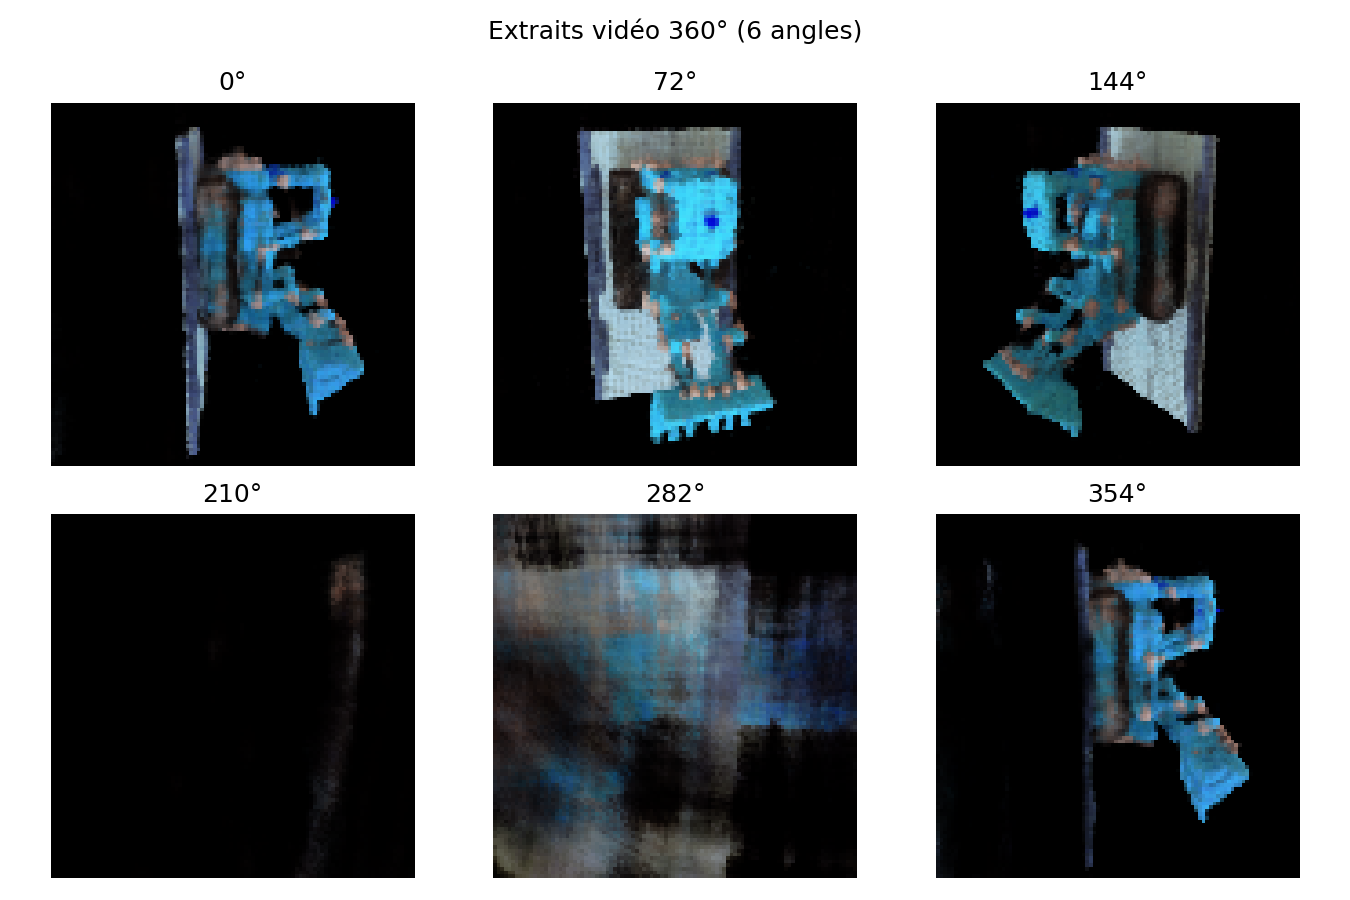

In [ ]:
# CELLULE 8 — Vidéo 360°
from IPython.display import Image, display

generer_video_360(
    modele,
    historique["enc_position"],
    historique["enc_direction"],
    chemin_sortie=str(DOSSIER_RESULTATS / "reconstruction_360.mp4"),
)

display(Image(filename=str(DOSSIER_RESULTATS / "grille_video_360.png")))

In [ ]:
# ============================================================
# RUN MULTI-SCENES (lego, chair, ficus)
# ============================================================
from pathlib import Path
import numpy as np

SCENES = ["lego", "chair", "ficus"]   # tu peux modifier cette liste
NB_ITER = 2000                        # 1000 rapide, 5000 qualité
TAILLE = (100, 100)

# Hyperparams entraînement
TAILLE_BATCH = 1024
NB_POINTS = 64
LR = 5e-4
PROCHE, LOIN = 2.0, 6.0

resume_runs = []

for scene in SCENES:
    print("\n" + "="*70)
    print(f"SCENE: {scene}")
    print("="*70)

    dossier_scene = RACINE / "data" / "nerf_synthetic" / scene
    if not dossier_scene.exists():
        print(f"[SKIP] Dossier introuvable: {dossier_scene}")
        continue

    # Dossiers de sortie par scène
    results_scene = DOSSIER_RESULTATS / scene
    ckpt_scene = DOSSIER_CHECKPOINTS / scene
    results_scene.mkdir(parents=True, exist_ok=True)
    ckpt_scene.mkdir(parents=True, exist_ok=True)

    # 1) Chargement
    images_train, poses_train, focale = charger_dataset(dossier_scene, "train", taille=TAILLE)
    images_test, poses_test, _ = charger_dataset(dossier_scene, "test", taille=TAILLE)
    print("train:", images_train.shape, "test:", images_test.shape, "focale:", round(focale, 3))

    # 2) Entraînement
    modele, historique = entrainer_nerf(
        images_train, poses_train, focale,
        nb_iterations=NB_ITER,
        taille_batch=TAILLE_BATCH,
        nb_points=NB_POINTS,
        lr=LR,
        proche=PROCHE,
        loin=LOIN,
        sauvegarder_tous=max(1000, NB_ITER // 2),
        dossier_checkpoints=str(ckpt_scene) + "/"
    )

    # 3) Courbes entraînement
    tracer_courbes_entrainement(
        historique["losses"],
        historique["psnrs"],
        historique["temps_par_iter"],
        chemin_sortie=str(results_scene / "training_curves.png"),
    )

    # 4) Benchmark
    resultats_benchmark = mesurer_speedup_gpu_vs_cpu(
        modele,
        historique["enc_position"],
        historique["enc_direction"],
        tailles_batch=[64, 128, 256, 512, 1024, 2048, 4096]
    )
    tracer_resultats_benchmark(
        resultats_benchmark,
        chemin_sortie=str(results_scene / "gpu_benchmark.png")
    )

    # 5) Évaluation
    psnr_moyen, ssim_moyen = evaluer_modele(
        modele,
        historique["enc_position"],
        historique["enc_direction"],
        images_test,
        poses_test,
        focale,
        nb_vues=4,
        chemin_grille=str(results_scene / "comparaison_vues.png"),
    )

    # 6) Vidéo 360
    generer_video_360(
        modele,
        historique["enc_position"],
        historique["enc_direction"],
        H=TAILLE[0],
        W=TAILLE[1],
        focale=focale,
        nb_frames=60,
        chemin_sortie=str(results_scene / "reconstruction_360.mp4"),
    )

    # Résumé scène
    t_moy = float(np.mean(historique["temps_par_iter"]))
    speedup_max = float(np.nanmax(resultats_benchmark["speedup"]))

    resume_runs.append({
        "scene": scene,
        "psnr": psnr_moyen,
        "ssim": ssim_moyen,
        "temps_iter_ms": t_moy,
        "speedup_max": speedup_max,
        "dossier": str(results_scene)
    })

print("\n\n===== RÉSUMÉ GLOBAL =====")
for r in resume_runs:
    print(
        f"{r['scene']:>8} | PSNR={r['psnr']:.2f} dB | SSIM={r['ssim']:.3f} "
        f"| temps/iter={r['temps_iter_ms']:.2f} ms | speedup_max={r['speedup_max']:.2f}x "
        f"| {r['dossier']}"
    )


SCENE: lego
[SKIP] Dossier introuvable: /content/drive/MyDrive/nerf_parallele/data/nerf_synthetic/lego

SCENE: chair
[SKIP] Dossier introuvable: /content/drive/MyDrive/nerf_parallele/data/nerf_synthetic/chair

SCENE: ficus
[SKIP] Dossier introuvable: /content/drive/MyDrive/nerf_parallele/data/nerf_synthetic/ficus


===== RÉSUMÉ GLOBAL =====


In [ ]:
from pathlib import Path

DATASET_ROOT = Path("/content/nerf_synthetic")
print("DATASET_ROOT =", DATASET_ROOT, "| existe ?", DATASET_ROOT.exists())
print("scènes dispo:", [p.name for p in DATASET_ROOT.iterdir() if p.is_dir()][:20])

DATASET_ROOT = /content/nerf_synthetic | existe ? True
scènes dispo: ['lego']


In [ ]:
!ls

drive  sample_data


In [ ]:
from IPython.display import HTML, display

# Lire le fichier HTML
with open('nerf_dashboard.html', 'r', encoding='utf-8') as f:
    html_content = f.read()

# Afficher directement inline
display(HTML(html_content))